# R12b. Scenario comparison on the β-route signature, with a combined w_GS + noise scenario

Follow-up to R12 (round-2 notebook). R12 found that the data's complete 11-parameter signature was atypical of
every single-route scenario (typicality p = 0) and that w_GS ↓ and noise ↓ competed. Two likely reasons:
1. the signature included the HFO parameters, whose change in the data is not part of any scenario;
2. the data may contain more than one route (the posterior shows both w_GS and noise falling).

R12b therefore
* compares scenarios on **signature subsets**: the identifiable β-route parameters (w_GS, σ_slow, log₁₀σ, g_ctx,
  k_d, w_TC), the β-route plus hyperdirect input, and all 11 (as in R12);
* adds a **combined scenario, w_GS ↓ + noise ↓**, simulated under the same four conditions (assumed constants,
  w_GG ×0.5, τ_S/τ_G ×0.8, BG delays ×1.25);
* reports, per condition and signature: held-out accuracy and confusion, the frequency with which each scenario is
  the most probable across a patient bootstrap of the data (the main result; LDA point probabilities saturate),
  the typicality p of the data under each scenario, and the per-parameter z-scores of the data relative to the
  best-fitting scenario (to show what makes the data atypical, if they are).

The single-route pairs are **reused** from R12 (`OUT_DIR/revision/R12_pairs_*.npz`); only the combined scenario is
simulated (≈ 1700 simulations, ≈ 15–20 min). Total ≈ pipeline load + 25–35 min.

## 0. Settings

In [1]:
from pathlib import Path

REV_SCRIPT = Path(r"revision_analyses.py")    # ← round-1 script (the version with RUN_ONLY), same folder
PIPELINE = r"pd_pac_v51_circuit.py"
DS_ROOT = r"<local path>"                 # ← your ds004998 path
OUT_DIR = r"pd_pac_v4_outputs"                # ← same output folder (caches and R12_pairs_*.npz)
GPU_ID = 1
QUICK = False

K_PAIRS = 6                # must equal K_PAIRS of the R12 run
N_BOOT = 1000
SEED3 = 20261122
R12_CONDITIONS = ["assumed (no misspecification)", "w_GG ×0.5", "τ_S, τ_G ×0.8", "BG delays ×1.25"]   # same order as R12
COMBINED_RANGES = dict(w_GS=(0.6, 0.95), noise=(0.02, 0.20))   # w_GS × U(a, b);  Δlog10σ = −U(a, b)

## 1. Load the frozen pipeline and helper functions

In [ ]:
import re

src = REV_SCRIPT.read_text(encoding="utf-8")
OVR = {"PIPELINE": f"Path(r\"{PIPELINE}\")", "DS_ROOT": f"r\"{DS_ROOT}\"", "OUT_DIR": f"r\"{OUT_DIR}\"", "GPU_ID": str(GPU_ID),
       "QUICK": str(QUICK), "RUN_OXFORD_REV": "False", "RUN_ONLY": "set()"}
for name, value in OVR.items():
    line = f"{name} = {value}"
    src, n = re.subn(rf"^{name}\s*=.*$", lambda _m, line=line: line, src, count=1, flags=re.M)
    assert n == 1, f"could not find the setting {name} in {REV_SCRIPT}"
exec(compile(src, str(REV_SCRIPT), "exec"), globals())
RUN_ONLY = None

In [3]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.covariance import LedoitWolf

KEYS = [k for k in FS_DS if k in JS_DS]               # same order as in R12
SUBJ = np.array([k[0] for k in KEYS]); SUBS = pd.unique(SUBJ)
KG = JP.index("w_GS"); G0 = len(JP)
SINGLE = ["nuisance only", "noise ↓", "slow input ↓", "w_GS ↓"]
COMB = "w_GS ↓ + noise ↓"
SCEN = SINGLE + [COMB]
SIGS = {"β-route (6)": ["w_GS", "sig_slow", "log10_sig", "g_ctx", "k_d", "w_TC"],
        "β-route + hyperdirect (7)": ["w_GS", "sig_slow", "log10_sig", "g_ctx", "k_d", "w_TC", "w_CS"],
        "all 11 (as R12)": list(JP)}
print(f"{len(KEYS)} hemispheres, {len(SUBS)} patients; candidates: {JP}")
for nm, dims in SIGS.items():
    assert all(d in JP for d in dims), nm

36 hemispheres, 19 patients; candidates: ['w_GS', 'sig_slow', 'log10_sig', 'w_CS', 'w_TC', 'g_ctx', 'k_d', 'log10_aH', 'f_H', 'lam_H', 'chi_S']


## 2. Simulate the combined scenario (w_GS ↓ + noise ↓) under the four conditions

In [4]:
def R12b_simulate():
    base_c = dict(CIRC); out = {}
    for ci, cond in enumerate(R12_CONDITIONS):
        f_old = REV / f"R12_pairs_{ci}.npz"
        assert f_old.exists(), f"{f_old} not found: run R12 first (same OUT_DIR)"
        old = np.load(f_old, allow_pickle=True)
        assert set(np.unique(old["lab"])) == set(SINGLE), "R12 pairs do not match the expected scenarios"
        f_new = REV / f"R12b_combined_{ci}.npz"
        if f_new.exists():
            new = dict(np.load(f_new, allow_pickle=True)); print(f"[{cond}] combined scenario loaded from {f_new.name}")
        else:
            rng = np.random.default_rng(SEED3 + 100 * ci); TO, TN, hk, half = [], [], [], []
            for h, k in enumerate(KEYS):
                s_ = FS_DS[k]
                for r_ in range(K_PAIRS):
                    th = np.clip(s_[rng.integers(0, len(s_), 1), :nP], PRIOR_LO, PRIOR_HI)
                    Dm = np.zeros((1, nM))
                    Dm[0, KG] = np.log(rng.uniform(*COMBINED_RANGES["w_GS"]))
                    Dm[0, JP.index("log10_sig")] = -rng.uniform(*COMBINED_RANGES["noise"])
                    TO.append(th); TN.append(apply_full(th, Dm, nuisance_draw(th, rng))); hk.append(h); half.append(r_ < K_PAIRS // 2)
            TO, TN = np.concatenate(TO), np.concatenate(TN)
            try:
                for kk, v in MISSPEC[cond].items():
                    CIRC[kk] = base_c[kk] * v
                print(f"[{cond}] simulating {len(TO)} combined-scenario pairs")
                S = simulate_stats(np.concatenate([TO, TN]), SEED3 + 1000 + ci)
            finally:
                CIRC.clear(); CIRC.update(base_c)
            F = pair_features(S[:len(TO)], S[len(TO):]); ok = np.isfinite(F).all(1)
            MU = np.full((len(F), len(JP)), np.nan)
            for i in np.where(ok)[0]:
                MU[i] = joint_samples(JPOST, F[i], 1000)[:, G0:].mean(0)
            g = np.isfinite(MU).all(1)
            new = dict(MU=MU[g], lab=np.array([COMB] * g.sum()), hk=np.array(hk)[g], half=np.array(half)[g])
            np.savez(f_new, **new)
        out[cond] = dict(MU=np.concatenate([old["MU"], new["MU"]]), lab=np.concatenate([old["lab"].astype(str), new["lab"].astype(str)]),
                         hk=np.concatenate([old["hk"], new["hk"]]), half=np.concatenate([old["half"], new["half"]]))
    return out


PAIRS = None


def R12b_load():
    global PAIRS
    PAIRS = R12b_simulate()


run(R12b_load)

[assumed (no misspecification)] simulating 216 combined-scenario pairs
  432 sims: 100.0%  (  235 s)
    statistics: 80 s
[w_GG ×0.5] simulating 216 combined-scenario pairs
  432 sims: 100.0%  (  237 s)
    statistics: 78 s
[τ_S, τ_G ×0.8] simulating 216 combined-scenario pairs
  432 sims: 100.0%  (  235 s)
    statistics: 77 s
[BG delays ×1.25] simulating 216 combined-scenario pairs
  432 sims: 100.0%  (  240 s)
    statistics: 85 s
[R12b_load: 24.6 min]


## 3. Scenario comparison by signature subset and condition


===== signature: β-route (6) =====
held-out accuracy: assumed 0.949, w_GG ×0.5 0.875, τ_S, τ_G ×0.8 0.906, BG delays ×1.25 0.881
frequency of being the most probable scenario across the patient bootstrap of the data:
condition         assumed (no misspecification)  w_GG ×0.5  τ_S, τ_G ×0.8  BG delays ×1.25
scenario                                                                                  
nuisance only                             0.061      0.126          0.113            0.144
noise ↓                                   0.182      0.165          0.310            0.360
slow input ↓                              0.031      0.094          0.010            0.090
w_GS ↓                                    0.663      0.175          0.371            0.166
w_GS ↓ + noise ↓                          0.063      0.440          0.196            0.240
typicality p of the data (fraction of simulated cohorts at least as far from the scenario mean; small = atypical):
condition         assumed (no 

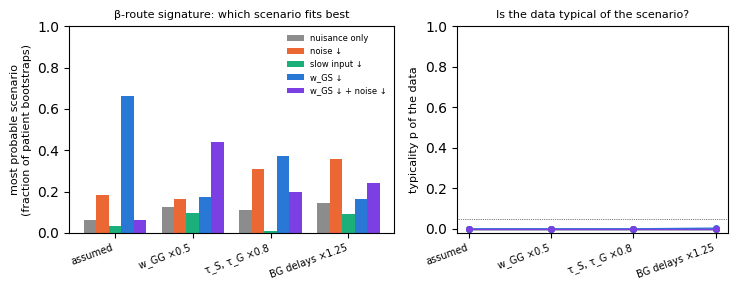

[R12b: 0.2 min]


In [5]:
def cohorts(P, cols, half, n, rng, scen=SCEN):
    X, y = [], []
    for si, sc in enumerate(scen):
        pools = [np.where((P["lab"] == sc) & (P["hk"] == h) & (P["half"] == half))[0] for h in range(len(KEYS))]
        pools = [p for p in pools if len(p)]
        for _ in range(n):
            X.append(np.mean([P["MU"][p[rng.integers(len(p))]][cols] for p in pools], 0)); y.append(si)
    return np.array(X), np.array(y)


def boot_signatures(MU_dat, cols, n, seed):
    rb = np.random.default_rng(seed); out = []
    for _ in range(n):
        ss = rb.choice(SUBS, len(SUBS)); idx = np.concatenate([np.where(SUBJ == s_)[0] for s_ in ss])
        out.append(MU_dat[idx][:, cols].mean(0))
    return np.array(out)


def R12b():
    MU_dat = np.array([JS_DS[k][:, G0:].mean(0) for k in KEYS])
    rows, conf, zrows, robust = [], [], [], []
    for sig, dims in SIGS.items():
        cols = [JP.index(d) for d in dims]
        sig_dat = MU_dat[:, cols].mean(0); SB = boot_signatures(MU_dat, cols, N_BOOT, SEED3 + 9)
        for cond in R12_CONDITIONS:
            P = PAIRS[cond]; rng = np.random.default_rng(SEED3 + 7)
            Xtr, ytr = cohorts(P, cols, True, 600, rng); Xte, yte = cohorts(P, cols, False, 300, rng)
            mu_, sd_ = Xtr.mean(0), Xtr.std(0) + 1e-12
            clf = LinearDiscriminantAnalysis(solver="eigen", shrinkage="auto").fit((Xtr - mu_) / sd_, ytr)
            pred = clf.predict((Xte - mu_) / sd_)
            C = pd.crosstab(pd.Series([SCEN[i] for i in yte], name="true"), pd.Series([SCEN[i] for i in pred], name="classified"),
                            normalize="index").reindex(index=SCEN, columns=SCEN, fill_value=0)
            conf.append(C.assign(signature=sig, condition=cond))
            p_dat = clf.predict_proba(((sig_dat - mu_) / sd_)[None])[0]
            PB = clf.predict_proba((SB - mu_) / sd_)
            for si, sc in enumerate(SCEN):
                Xs = (Xte[yte == si] - mu_) / sd_; m_ = Xs.mean(0)
                ci_ = np.linalg.pinv(LedoitWolf().fit((Xtr[ytr == si] - mu_) / sd_).covariance_)
                dm = lambda x: float((x - m_) @ ci_ @ (x - m_))
                d_dat = dm((sig_dat - mu_) / sd_)
                typ = np.mean([dm(x) >= d_dat for x in Xs])
                d_boot = np.median([dm((b - mu_) / sd_) for b in SB[:200]])
                typ_boot = np.mean([dm(x) >= d_boot for x in Xs])
                rows.append(dict(signature=sig, condition=cond, scenario=sc, heldout_accuracy=np.mean(pred == yte), recall=C.loc[sc, sc],
                                 P_data=p_dat[si], frac_boot_most_probable=np.mean(PB.argmax(1) == si),
                                 typicality_p=typ, typicality_p_bootmedian=typ_boot))
                if sig == list(SIGS)[0]:
                    Xr = Xte[yte == si]
                    zrows.append(dict(condition=cond, scenario=sc, **{f"z_{d}": (sig_dat[j] - Xr[:, j].mean()) / Xr[:, j].std() for j, d in enumerate(dims)}))
            # robustness: classifier trained under the assumed constants, applied to this condition
            if cond != R12_CONDITIONS[0]:
                A = PAIRS[R12_CONDITIONS[0]]; ra = np.random.default_rng(SEED3 + 8)
                Xa, ya = cohorts(A, cols, True, 600, ra); ma, sa = Xa.mean(0), Xa.std(0) + 1e-12
                ca = LinearDiscriminantAnalysis(solver="eigen", shrinkage="auto").fit((Xa - ma) / sa, ya)
                pr = ca.predict((Xte - ma) / sa)
                for si, sc in enumerate(SCEN):
                    robust.append(dict(signature=sig, condition=cond, true_scenario=sc,
                                       **{f"→ {s2}": np.mean(pr[yte == si] == j) for j, s2 in enumerate(SCEN)}))
    T = pd.DataFrame(rows); T.to_csv(REV / "R12b_scenario_comparison.csv", index=False)
    pd.concat(conf).to_csv(REV / "R12b_confusion.csv"); Z = pd.DataFrame(zrows); Z.to_csv(REV / "R12b_zscores_beta_route.csv", index=False)
    pd.set_option("display.width", 250)
    for sig in SIGS:
        t = T[T.signature == sig]
        print(f"\n===== signature: {sig} =====")
        print("held-out accuracy: " + ", ".join(f"{c.split(' (')[0]} {t[t.condition == c].heldout_accuracy.iloc[0]:.3f}" for c in R12_CONDITIONS))
        print("frequency of being the most probable scenario across the patient bootstrap of the data:")
        print(t.pivot(index="scenario", columns="condition", values="frac_boot_most_probable").loc[SCEN, R12_CONDITIONS].round(3).to_string())
        print("typicality p of the data (fraction of simulated cohorts at least as far from the scenario mean; small = atypical):")
        print(t.pivot(index="scenario", columns="condition", values="typicality_p").loc[SCEN, R12_CONDITIONS].round(3).to_string())
    print("\nβ-route signature: z-scores of the data relative to each scenario's simulated cohorts (|z| > 3: the data lie outside)")
    print(Z.round(2).to_string(index=False))
    if robust:
        R = pd.DataFrame(robust); R.to_csv(REV / "R12b_misspecified_with_assumed_classifier.csv", index=False)
        print("\nClassifier trained under the assumed constants, applied to misspecified cohorts (β-route signature):")
        print(R[R.signature == list(SIGS)[0]].drop(columns="signature").round(3).to_string(index=False))
    SUMMARY["R12b"] = T
    # figure: β-route signature, bootstrap frequency of most-probable scenario + typicality
    t = T[T.signature == list(SIGS)[0]]
    cols_ = ["#8c8c8c", "#eb6834", "#1baf7a", "#2a78d6", "#7b3fe4"]
    fig, axs = plt.subplots(1, 2, figsize=(7.48, 3.0), gridspec_kw=dict(width_ratios=[1.2, 1]))
    x = np.arange(len(R12_CONDITIONS)); wdt = 0.16
    for si, sc in enumerate(SCEN):
        s = t[t.scenario == sc].set_index("condition").loc[R12_CONDITIONS]
        axs[0].bar(x + (si - 2) * wdt, s.frac_boot_most_probable, wdt, color=cols_[si], label=sc)
        axs[1].plot(x, s.typicality_p, "o-", color=cols_[si], ms=4, lw=1, label=sc)
    lbl = [c.replace("assumed (no misspecification)", "assumed") for c in R12_CONDITIONS]
    axs[0].set_xticks(x, lbl, rotation=20, ha="right", fontsize=7); axs[0].set_ylim(0, 1)
    axs[0].set_ylabel("most probable scenario\n(fraction of patient bootstraps)", fontsize=8); axs[0].legend(frameon=False, fontsize=6)
    axs[1].set_xticks(x, lbl, rotation=20, ha="right", fontsize=7); axs[1].set_ylim(-0.02, 1); axs[1].axhline(.05, color="k", lw=.5, ls=":")
    axs[1].set_ylabel("typicality p of the data", fontsize=8)
    axs[0].set_title("β-route signature: which scenario fits best", fontsize=8); axs[1].set_title("Is the data typical of the scenario?", fontsize=8)
    fig.tight_layout(); fig.savefig(REVF / "R12b_scenarios.png", dpi=300); plt.show()


run(R12b)